# Exercise 1 (Total 30 points)

Remember -> submission using itslearning *deadline on 30.10.2026*

# Setup
Common imports and a small helper to download the UCI datasets.
The helper first looks for the file in the notebook folder. If it is not there, it downloads the zip file from the UCI repository and extracts the file we need. (If the download fails, download the zip manually from the URL and put the file next to the notebook.)

In [1]:
import os, io, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=DeprecationWarning)   

def get_uci_file(fname, zip_url):
    """Return a local path to `fname`; download and extract it from the UCI zip if needed."""
    if not os.path.exists(fname):
        print("Downloading", zip_url)
        with urllib.request.urlopen(zip_url) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        member = [n for n in z.namelist() if n.endswith(fname)][0]
        with open(fname, "wb") as f:
            f.write(z.read(member))
    return fname

## Task 1 (5 points): Regression

##### Dataset: Superconductivity 
* Number of records: 21263 
* Number of features: 81 + 1 (target/output feature) 
* Repository URL: https://archive.ics.uci.edu/ml/datasets/Superconductivty+Data

##### Problems
__a.__ Train two regression models to predict the critical temperature. Report the score with the default parameters of each model.\
__b.__ Perform a simple manual optimization for one of the default parameters (at least 5 different values) and plot the new obtained scores as a function of the chosen parameter. Plot the coefficient magnitudes for the best obtained model.

---
#  Task 1: Regression 
### Load and explore the data
Each row is one superconducting material. The 81 features are statistics (mean, weighted mean, entropy, range, std…) of properties of the chemical elements in the material (atomic mass, radius, valence, thermal conductivity, …). The target `critical_temp` is the critical temperature in Kelvin.

Shape: (21263, 82)
count    21263.00
mean        34.42
std         34.25
min          0.00
25%          5.36
50%         20.00
75%         63.00
max        185.00
Name: critical_temp, dtype: float64


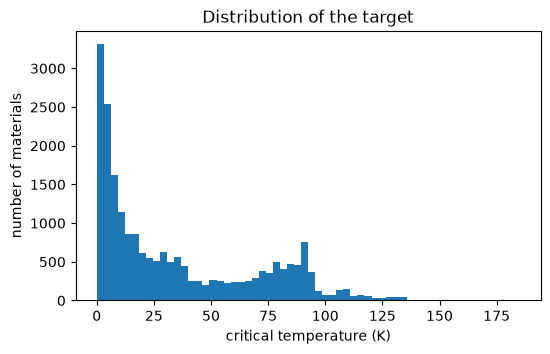

In [3]:
path = get_uci_file("train.csv",
                    "https://archive.ics.uci.edu/static/public/464/superconductivty+data.zip")
sc_df = pd.read_csv(path)
print("Shape:", sc_df.shape)
print(sc_df["critical_temp"].describe().round(2))

X_sc = sc_df.drop(columns="critical_temp")
y_sc = sc_df["critical_temp"].values
feature_names_sc = X_sc.columns

plt.figure(figsize=(6, 3.5))
plt.hist(y_sc, bins=60)
plt.xlabel("critical temperature (K)"); plt.ylabel("number of materials")
plt.title("Distribution of the target")
plt.show()

### Split and scale
* 75 % training / 25 % test. The test set is used only to report the final scores.
* Linear models with regularization need features on the same scale (the features here range from ~0.1 to several thousands), so we standardize them with `StandardScaler`. The scaler is **fitted on the training set only**, so no information from the test set leaks into the model. Tree models do not need scaling, but scaling does not harm them either, so we use the scaled data for both models.

In [4]:
Xsc_train, Xsc_test, ysc_train, ysc_test = train_test_split(
    X_sc.values, y_sc, test_size=0.25, random_state=RANDOM_STATE)

scaler_sc = StandardScaler().fit(Xsc_train)
Xsc_train_s = scaler_sc.transform(Xsc_train)
Xsc_test_s  = scaler_sc.transform(Xsc_test)
print("train:", Xsc_train_s.shape, " test:", Xsc_test_s.shape)

train: (15947, 81)  test: (5316, 81)


### a. Two regression models with default parameters
1. **Lasso**: a linear model with L1 regularization (default `alpha=1.0`). L1 can set some coefficients exactly to zero, so it also selects features.
2. **Random forest regressor**: an ensemble of 100 decision trees (default). It can model non-linear relations between the features and the target.

We report **R²** (`.score()`, 1 = perfect) and the **RMSE** (root mean squared error, in Kelvin), which is easier to interpret.
(`n_jobs=-1` only uses all CPU cores to train faster; it does not change the model.)

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

def report_reg(name, model, Xtr, ytr, Xte, yte):
    rmse = np.sqrt(mean_squared_error(yte, model.predict(Xte)))
    print("{:<28} train R²: {:.3f}   test R²: {:.3f}   test RMSE: {:.1f} K".format(
        name, model.score(Xtr, ytr), model.score(Xte, yte), rmse))

lasso_default = Lasso().fit(Xsc_train_s, ysc_train)
report_reg("Lasso (default)", lasso_default, Xsc_train_s, ysc_train, Xsc_test_s, ysc_test)
print("   non-zero coefficients:", np.sum(lasso_default.coef_ != 0), "of", len(lasso_default.coef_))

rf_reg = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1).fit(Xsc_train_s, ysc_train)
report_reg("RandomForest (default)", rf_reg, Xsc_train_s, ysc_train, Xsc_test_s, ysc_test)

### Comments (a)
* **Lasso (default `alpha=1`)** explains about 65 % of the variance of the critical temperature (test R² ≈ 0.65, RMSE ≈ 20 K, while the target has a standard deviation of ≈ 34 K). Train and test R² are almost equal, so the model does **not** overfit. It **underfits**: with `alpha=1` the L1 penalty is strong and keeps only 17 of the 81 features, and a linear model cannot capture the non-linear relation between the element properties and the temperature.
* **Random forest (default)** is much better: test R² ≈ 0.93 and RMSE ≈ 9 K, i.e. the typical error is more than halved. Its training R² (≈ 0.98) is higher than the test R², which shows some overfitting (fully grown trees), but the test score is still by far the best. This tells us that the problem is strongly **non-linear**.

### b. Manual optimization of `alpha` (Lasso)
We tune `alpha`, the regularization strength of Lasso, with 7 values from 0.001 to 5.
To choose `alpha` fairly, we do **not** look at the test set. We split the training set again into a *fit* part (75 %) and a *validation* part (25 %), choose the `alpha` with the best validation R², and only at the end check the chosen model on the test set.

In [ ]:
Xfit, Xval, yfit, yval = train_test_split(Xsc_train_s, ysc_train, test_size=0.25, random_state=RANDOM_STATE)

alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5]
fit_scores, val_scores, n_nonzero = [], [], []
for a in alphas:
    m = Lasso(alpha=a, max_iter=50000).fit(Xfit, yfit)
    fit_scores.append(m.score(Xfit, yfit))
    val_scores.append(m.score(Xval, yval))
    n_nonzero.append(np.sum(m.coef_ != 0))

print(pd.DataFrame({"alpha": alphas, "fit R²": fit_scores, "validation R²": val_scores,
                    "non-zero coefs": n_nonzero}).round(4).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(alphas, fit_scores, "o-", label="fit (training) R²")
ax1.plot(alphas, val_scores, "s-", label="validation R²")
ax1.set_xscale("log"); ax1.set_xlabel("alpha (log scale)"); ax1.set_ylabel("R²")
ax2 = ax1.twinx()
ax2.bar(alphas, n_nonzero, width=np.array(alphas) * 0.4, alpha=0.2, color="gray", label="non-zero coefficients")
ax2.set_ylabel("number of non-zero coefficients")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left")
plt.title("Lasso: score as a function of alpha")
plt.show()

Re-train Lasso with the best `alpha` on the whole training set and evaluate it once on the test set.

In [ ]:
best_alpha = alphas[int(np.argmax(val_scores))]
lasso_best = Lasso(alpha=best_alpha, max_iter=50000).fit(Xsc_train_s, ysc_train)
print("Best alpha:", best_alpha)
report_reg("Lasso (alpha={})".format(best_alpha), lasso_best, Xsc_train_s, ysc_train, Xsc_test_s, ysc_test)
print("   non-zero coefficients:", np.sum(lasso_best.coef_ != 0), "of", len(lasso_best.coef_))

### Coefficient magnitudes of the best model
Because all features were standardized, the coefficients are comparable: each coefficient is the change in predicted temperature (K) when the feature increases by one standard deviation, all other features fixed. The first plot shows all 81 coefficients; the second one zooms in on the 20 largest.

In [ ]:
coefs = pd.Series(lasso_best.coef_, index=feature_names_sc)

plt.figure(figsize=(14, 4))
plt.bar(range(len(coefs)), coefs.values)
plt.xticks(range(len(coefs)), coefs.index, rotation=90, fontsize=6)
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("coefficient"); plt.title("Lasso (alpha={}) – all coefficients".format(best_alpha))
plt.show()

top = coefs.reindex(coefs.abs().sort_values(ascending=True).index)[-20:]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=np.where(top.values > 0, "tab:blue", "tab:red"))
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("coefficient (blue = positive, red = negative)")
plt.title("20 largest coefficient magnitudes")
plt.tight_layout(); plt.show()

### Comments (b)
* **Score vs alpha:** the smaller `alpha`, the weaker the regularization, the more features are kept and the higher the score. Up to `alpha ≈ 0.01` the validation R² stays around 0.745 and almost all features are used. With larger `alpha` many coefficients become exactly zero (5 features left at `alpha=5`) and both training and validation R² fall (≈ 0.55 at `alpha=5`). The training and validation curves stay close for all values, so even the weakest regularization does not overfit: with ~16 000 samples and only 81 features, a linear model has little room to overfit.
* **Best model:** `alpha=0.001` gives a test R² ≈ 0.73 (RMSE ≈ 18 K), better than the default Lasso (0.65), but still far below the random forest (0.93). Tuning a parameter cannot fix the main limitation of the linear model: the relation is not linear.
* **Coefficients:** the largest coefficients come in pairs of almost identical features with **opposite signs**, e.g. `wtd_gmean_atomic_radius` (≈ −77) and `wtd_mean_atomic_radius` (≈ +73), or the weighted mean / geometric mean of valence and atomic mass. These features are very strongly **correlated** (multicollinearity), so the model can give one a large positive weight and the other a large negative weight that almost cancel. Therefore the size of an individual coefficient should **not** be read as the importance of that feature. A stronger `alpha` (e.g. 0.1) gives a simpler, more interpretable model with fewer features at the cost of some accuracy (validation R² ≈ 0.72 with 43 features).

## Task 2 (10 points): Multiclass & binary classification 

##### Dataset:  Drug consumption (quantified)
* Number of records: 1885
* Number of features: 12 + 18 (target/output features)
* Repository URL: https://archive.ics.uci.edu/ml/datasets/Drug+consumption+%28quantified%29
* Reference: Fehrman, Elaine, Awaz K. Muhammad, Evgeny M. Mirkes, Vincent Egan, and Alexander N. Gorban. "The five factor model of personality and evaluation of drug consumption risk." In Data science: innovative developments in data analysis and clustering, pp. 231-242. Springer International Publishing, 2017.

##### Problems
__a.__ Select 2 out of 18 output features, then predict each selected feature by using a multiclass classification model. (Hint: Use numerical values to represent each class of an output feature) Report the accuracy with the default parameters of each model. (__Note__: two different multiclass classification models must be used) \
__b.__ Perform a simple manual optimization for one of the default parameters (at least 5 different values) for one of the previous models. Plot the obtained accuracy as a function of the chosen parameter. \
__c.__ Train one multiclass classification model to predict 16 output features (exclude 2 output features from a). Comment on the accuracy of predicting each feature, for all the 7 classes. \
__d.__ Run one binary classification model for 3 out of 18 output features. Evaluate the performance of the model with different setups as follows. 
 - (class 0) the variables "Never Used" and "Used Over a Decade" and (class 1) the remaining variables.
 - (class 0) the variables "Never Used", "Used Over a Decade" and "Used in Last Decade" and (class 1) the remaining variables.
 - (class 0) the variables "Never Used", "Used over a Decade", "Used in Last Decade" and "Used in Last Year" and (class 1) the remaining variables.
 
__NOTE__: Comment your results, and the best setups in d.

---
# Solution Task 2: Multiclass & binary classification (Drug consumption)
### Load and prepare the data
* Column 0 is an ID (not a feature, we drop it).
* The 12 input features (age, gender, education, country, ethnicity, the five personality scores N/E/O/A/C, impulsiveness and sensation seeking) are already **quantified** by the authors, i.e. converted to real numbers, so they can be used directly.
* The output columns contain classes `CL0`…`CL6`. As the hint suggests, we convert them to the numbers 0–6.
* The file has **19** drug columns. One of them, **Semeron**, is a fictitious drug that the authors added to detect people who over-claim. The dataset description counts 18 real drugs, so we leave Semeron out.

In [8]:
features_dr = ["Age", "Gender", "Education", "Country", "Ethnicity", "Nscore", "Escore",
               "Oscore", "Ascore", "Cscore", "Impulsive", "SS"]
all_drug_cols = ["Alcohol", "Amphet", "Amyl", "Benzos", "Caff", "Cannabis", "Choc", "Coke",
                 "Crack", "Ecstasy", "Heroin", "Ketamine", "Legalh", "LSD", "Meth",
                 "Mushrooms", "Nicotine", "Semer", "VSA"]
class_names = ["Never used", "Over a decade ago", "In last decade", "In last year",
               "In last month", "In last week", "In last day"]

path = get_uci_file("drug_consumption.data",
                    "https://archive.ics.uci.edu/static/public/373/drug+consumption+quantified.zip")
dr = pd.read_csv(path, header=None, names=["ID"] + features_dr + all_drug_cols)
for c in all_drug_cols:
    dr[c] = dr[c].str.replace("CL", "").astype(int)      # 'CL3' -> 3

drugs = [d for d in all_drug_cols if d != "Semer"]       # the 18 real drugs
print("Shape:", dr.shape, "-> 12 features,", len(drugs), "drugs used")

counts = pd.DataFrame({d: dr[d].value_counts().sort_index() for d in drugs}).T.fillna(0).astype(int)
counts.columns = class_names
counts

Shape: (1885, 32) -> 12 features, 18 drugs used


,Never used,Over a decade ago,In last decade,In last year,In last month,In last week,In last day
Alcohol,34,34,68,198,287,759,505
Amphet,976,230,243,198,75,61,102
Amyl,1305,210,237,92,24,14,3
Benzos,1000,116,234,236,120,84,95
Caff,27,10,24,60,106,273,1385
Cannabis,413,207,266,211,140,185,463
Choc,32,3,10,54,296,683,807
Coke,1038,160,270,258,99,41,19
Crack,1627,67,112,59,9,9,2
Ecstasy,1021,113,234,277,156,63,21


The table above shows that the classes are **imbalanced** and very different between drugs: e.g. almost everybody used chocolate or caffeine recently, while most people never used crack or heroin. So, for each prediction we compare the accuracy with a **baseline** that always predicts the most frequent class of the training set. A model is only useful if it beats this baseline.

### Split and scale
We use one train/test split (75 % / 25 %) for the whole task, so all drugs are evaluated on the same people. The features are standardized for the logistic regression (fitted on the training set only).

In [9]:
Xdr = dr[features_dr].values
idx_train, idx_test = train_test_split(np.arange(len(dr)), test_size=0.25, random_state=RANDOM_STATE)
Xdr_train, Xdr_test = Xdr[idx_train], Xdr[idx_test]

scaler_dr = StandardScaler().fit(Xdr_train)
Xdr_train_s, Xdr_test_s = scaler_dr.transform(Xdr_train), scaler_dr.transform(Xdr_test)

def baseline_acc(y_tr, y_te):
    """Accuracy of always predicting the most frequent training class."""
    return np.mean(y_te == pd.Series(y_tr).mode()[0])

print("train:", Xdr_train.shape, " test:", Xdr_test.shape)

train: (1413, 12)  test: (472, 12)


### a. Two multiclass models for two drugs (Cannabis and Nicotine)
We choose **Cannabis** and **Nicotine** because their 7 classes are much more evenly spread than for most drugs, so the multiclass problem is meaningful.
* **Logistic regression** (multinomial, default `C=1`) on scaled data.
* **Random forest classifier** (default 100 trees).

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

selected = ["Cannabis", "Nicotine"]
rows = []
for drug in selected:
    y_tr, y_te = dr[drug].values[idx_train], dr[drug].values[idx_test]
    logreg = LogisticRegression(max_iter=5000).fit(Xdr_train_s, y_tr)
    rf = RandomForestClassifier(random_state=RANDOM_STATE).fit(Xdr_train, y_tr)
    rows.append({"drug": drug,
                 "baseline (most frequent)": baseline_acc(y_tr, y_te),
                 "LogisticRegression": logreg.score(Xdr_test_s, y_te),
                 "RandomForest": rf.score(Xdr_test, y_te),
                 "RF train accuracy": rf.score(Xdr_train, y_tr)})
pd.DataFrame(rows).set_index("drug").round(3)

,baseline (most frequent),LogisticRegression,RandomForest,RF train accuracy
drug,,,,
Cannabis,0.252,0.413,0.381,1.0
Nicotine,0.320,0.379,0.375,1.0


### Comments (a)
* For both drugs the models beat the baseline, but the accuracy is **low**: about 0.38–0.41 for Cannabis (baseline 0.25) and about 0.38 for Nicotine (baseline 0.32). Predicting the exact one of 7 usage classes from demographics and personality scores is hard: neighbouring classes (e.g. "used in last month" vs "in last week") are very similar people, and personality does not decide *when* someone last used a drug.
* Logistic regression is slightly better than the random forest here. The random forest has **100 % training accuracy** but only ≈ 0.38 test accuracy, a clear sign of **overfitting** with default parameters (trees grow without depth limit). This motivates tuning `max_depth` in (b).

### b. Manual optimization of `max_depth` (Random forest, Cannabis)
`max_depth` limits how deep each tree can grow (default `None` = no limit). As in Task 1, we choose the value on a **validation** split taken from the training set, and only then evaluate the chosen model on the test set.

max_depth  fit accuracy  validation accuracy
        1         0.402                0.429
        2         0.406                0.421
        3         0.417                0.429
        5         0.498                0.432
        8         0.807                0.444
       12         0.980                0.444
     None         1.000                0.412


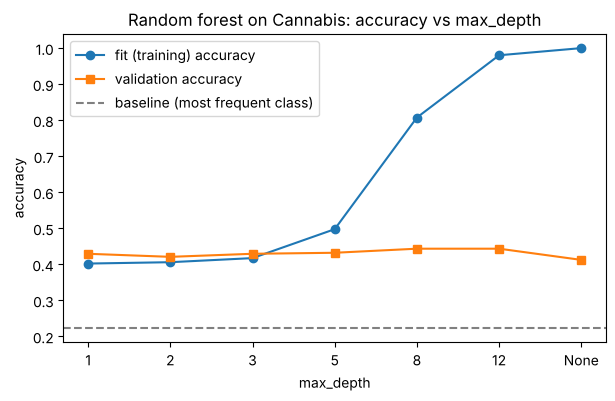

Best max_depth: 8 -> test accuracy: 0.409


In [11]:
y_tr, y_te = dr["Cannabis"].values[idx_train], dr["Cannabis"].values[idx_test]
Xf, Xv, yf, yv = train_test_split(Xdr_train, y_tr, test_size=0.25, random_state=RANDOM_STATE)

depths = [1, 2, 3, 5, 8, 12, None]
fit_acc, val_acc = [], []
for depth in depths:
    m = RandomForestClassifier(max_depth=depth, random_state=RANDOM_STATE).fit(Xf, yf)
    fit_acc.append(m.score(Xf, yf)); val_acc.append(m.score(Xv, yv))

labels = [str(d) for d in depths]
print(pd.DataFrame({"max_depth": labels, "fit accuracy": fit_acc, "validation accuracy": val_acc}).round(3).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(labels, fit_acc, "o-", label="fit (training) accuracy")
plt.plot(labels, val_acc, "s-", label="validation accuracy")
plt.axhline(baseline_acc(yf, yv), ls="--", color="gray", label="baseline (most frequent class)")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend()
plt.title("Random forest on Cannabis: accuracy vs max_depth")
plt.show()

best_depth = depths[int(np.argmax(val_acc))]
rf_best = RandomForestClassifier(max_depth=best_depth, random_state=RANDOM_STATE).fit(Xdr_train, y_tr)
print("Best max_depth:", best_depth, "-> test accuracy: {:.3f}".format(rf_best.score(Xdr_test, y_te)))

### Comments (b)
* With small depths (1–3) the forest is too simple: training and validation accuracy are both ≈ 0.40–0.43 (underfitting).
* As `max_depth` grows, the **training** accuracy rises quickly (0.81 at depth 8, 1.00 without limit), but the **validation** accuracy hardly changes (0.41–0.44). The gap between the two curves is overfitting: deep trees memorize the training people.
* The best validation accuracy is reached at `max_depth=8` (≈ 0.44). Re-trained on the whole training set it gives a test accuracy of ≈ 0.41, a small improvement over the default forest (≈ 0.38). The gain is small: the limit of this problem is the information in the features, not the parameter.

### c. One multiclass model for the other 16 drugs
`RandomForestClassifier` supports **multi-output** classification: we give it a target matrix with 16 columns, and **one single model** predicts the 7-class label of all 16 drugs at once.

For each drug we report the overall accuracy, the baseline, and the **accuracy for each of the 7 classes**. The accuracy for class *k* is the share of test people whose true class is *k* who were predicted correctly (this is the *recall* of class *k*). The `n` table shows how many test people are in each class: if it is small, the per-class accuracy is not reliable.

In [12]:
other16 = [d for d in drugs if d not in selected]
Y_tr = dr[other16].values[idx_train]
Y_te = dr[other16].values[idx_test]

rf_multi = RandomForestClassifier(random_state=RANDOM_STATE).fit(Xdr_train, Y_tr)
Y_pred = rf_multi.predict(Xdr_test)

summary, per_class, support = [], {}, {}
for j, drug in enumerate(other16):
    yt, yp = Y_te[:, j], Y_pred[:, j]
    summary.append({"drug": drug, "accuracy": np.mean(yt == yp), "baseline": baseline_acc(Y_tr[:, j], yt)})
    per_class[drug] = [np.mean(yp[yt == k] == k) if np.any(yt == k) else np.nan for k in range(7)]
    support[drug] = [int(np.sum(yt == k)) for k in range(7)]

summary = pd.DataFrame(summary).set_index("drug")
summary["gain over baseline"] = summary["accuracy"] - summary["baseline"]
per_class = pd.DataFrame(per_class, index=class_names).T
support = pd.DataFrame(support, index=class_names).T
print("Overall accuracy per drug:")
print(summary.round(3).sort_values("accuracy", ascending=False).to_string())
print("\nNumber of test people per class (n):")
print(support.to_string())

Overall accuracy per drug:
           accuracy  baseline  gain over baseline
drug                                             
Crack         0.881     0.881               0.000
Heroin        0.862     0.860               0.002
Ketamine      0.799     0.801              -0.002
VSA           0.769     0.769               0.000
Meth          0.742     0.748              -0.006
Caff          0.739     0.739               0.000
Amyl          0.699     0.695               0.004
Legalh        0.591     0.551               0.040
LSD           0.574     0.572               0.002
Coke          0.572     0.559               0.013
Benzos        0.542     0.549              -0.006
Ecstasy       0.534     0.536              -0.002
Mushrooms     0.521     0.511               0.011
Amphet        0.500     0.517              -0.017
Choc          0.396     0.407              -0.011
Alcohol       0.364     0.413              -0.049

Number of test people per class (n):
           Never used  Over a decad

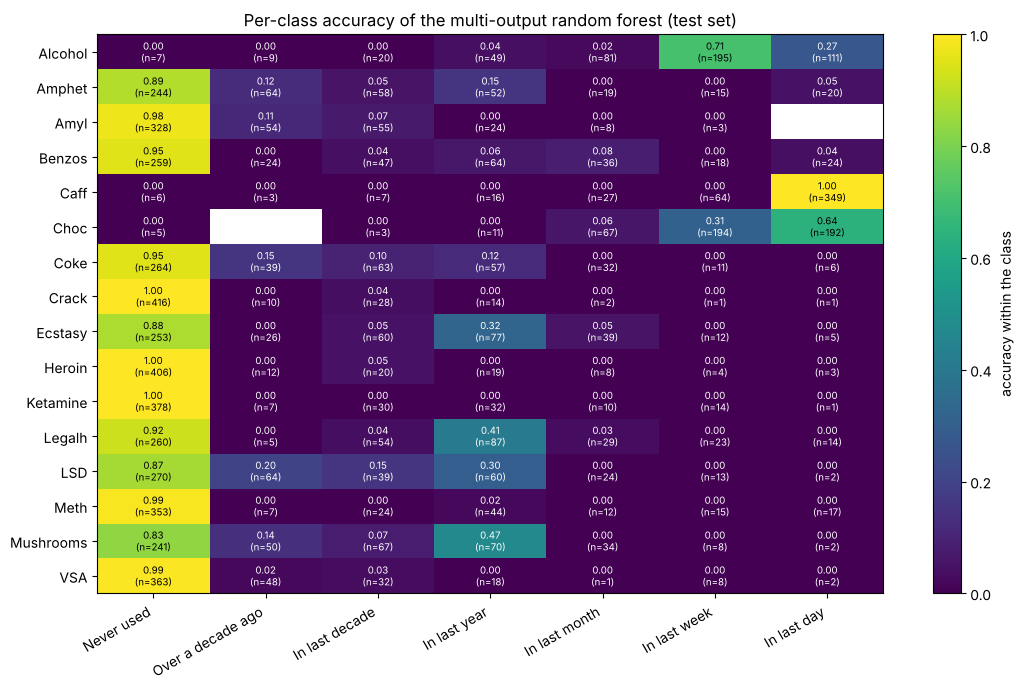

In [13]:
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(per_class.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(7)); ax.set_xticklabels(class_names, rotation=30, ha="right")
ax.set_yticks(range(len(other16))); ax.set_yticklabels(other16)
for i in range(len(other16)):
    for k in range(7):
        v, n = per_class.values[i, k], support.values[i, k]
        txt = "–" if np.isnan(v) else "{:.2f}\n(n={})".format(v, n)
        ax.text(k, i, txt, ha="center", va="center", fontsize=7,
                color="black" if (not np.isnan(v) and v > 0.6) else "white")
plt.colorbar(im, label="accuracy within the class")
plt.title("Per-class accuracy of the multi-output random forest (test set)")
plt.tight_layout(); plt.show()

### Comments (c)
* **Overall accuracy is misleading.** Crack (0.88), Heroin (0.86) and Ketamine (0.80) look very good, but their accuracy is **equal to the baseline**: almost all test people are "never used" and the model almost always predicts this class. Across the 16 drugs, the gain over the baseline is between about −0.05 and +0.04, i.e. the multi-output forest is essentially not better than predicting the most frequent class.
* **Per-class accuracy shows what really happens:**
  * For illegal drugs (Amphetamines, Benzodiazepines, Coke, Crack, Heroin, Ketamine, Meth, VSA, …) the accuracy of class **"Never used"** is very high (0.83–1.00), but the classes of real users are almost never recognized (mostly 0.00–0.15).
  * For legal, common substances the opposite happens: **Caffeine** gets 1.00 for "used in last day" and 0.00 for all other classes; **Chocolate** gets 0.64 / 0.31 for last day / last week; **Alcohol** gets 0.71 for "last week" and almost 0 for all other classes.
  * The only clear exceptions are "used in last year" for Mushrooms (0.47), Legal highs (0.41), Ecstasy (0.32) and LSD (0.30), and some recognition of "over a decade ago" for LSD (0.20). This suggests that these drugs share a similar user profile (high openness and sensation seeking).
  * Many classes have very few test people (n < 10, e.g. Crack, Heroin and Ketamine in the recent-use classes). Their per-class accuracy is not reliable, and the model has too few training examples to learn them.
* **Conclusion:** the 7-class problem is strongly **imbalanced**, and the model mainly learns the majority class of each drug. Merging classes into fewer, larger groups (part d) or using class weights / balanced metrics would be more appropriate.

### d. Binary classification for 3 drugs with 3 setups
We use **logistic regression** (scaled data, default parameters) for **Cannabis, Ecstasy and Nicotine**. The 7 classes are merged into "non-user" (0) and "user" (1) in three ways:

| Setup | class 0 | class 1 |
|---|---|---|
| 1 | CL0–CL1 (never, over a decade ago) | CL2–CL6 |
| 2 | CL0–CL2 (… in last decade) | CL3–CL6 |
| 3 | CL0–CL3 (… in last year) | CL4–CL6 |

Moving from setup 1 to 3, class 1 becomes a more *recent* (and rarer) use. Because the share of class 1 changes a lot between setups, accuracy alone can be misleading, so we also report:
* **baseline**: accuracy of always predicting the most frequent class;
* **balanced accuracy**: average of the accuracy on class 0 and on class 1 (0.5 = no better than guessing);
* **F1 (class 1)**: how well the model finds the users;
* **ROC AUC**: how well the predicted probabilities rank users above non-users (0.5 = random, 1 = perfect).

In [14]:
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score

binary_drugs = ["Cannabis", "Ecstasy", "Nicotine"]
setups = {1: 2, 2: 3, 3: 4}            # setup -> first class that counts as "1"
rows = []
for drug in binary_drugs:
    for s, first_pos in setups.items():
        yb = (dr[drug].values >= first_pos).astype(int)
        yb_tr, yb_te = yb[idx_train], yb[idx_test]
        clf = LogisticRegression(max_iter=5000).fit(Xdr_train_s, yb_tr)
        pred = clf.predict(Xdr_test_s); proba = clf.predict_proba(Xdr_test_s)[:, 1]
        rows.append({"drug": drug, "setup": s, "share of class 1": yb.mean(),
                     "accuracy": np.mean(pred == yb_te), "baseline": baseline_acc(yb_tr, yb_te),
                     "balanced acc.": balanced_accuracy_score(yb_te, pred),
                     "F1 (class 1)": f1_score(yb_te, pred), "ROC AUC": roc_auc_score(yb_te, proba)})
bin_res = pd.DataFrame(rows).set_index(["drug", "setup"]).round(3)
bin_res

share of class 1  accuracy  baseline  balanced acc.  F1 (class 1)  ROC AUC
drug     setup                                                                            
Cannabis 1                 0.671     0.824     0.701          0.807         0.871    0.885
         2                 0.530     0.792     0.566          0.796         0.808    0.886
         3                 0.418     0.786     0.581          0.780         0.744    0.865
Ecstasy  1                 0.398     0.731     0.591          0.715         0.656    0.796
         2                 0.274     0.744     0.718          0.648         0.485    0.798
         3                 0.127     0.881     0.881          0.500         0.000    0.758
Nicotine 1                 0.671     0.716     0.672          0.639         0.804    0.758
         2                 0.562     0.716     0.564          0.709         0.753    0.764
         3                 0.464     0.689     0.536          0.684         0.651    0.723

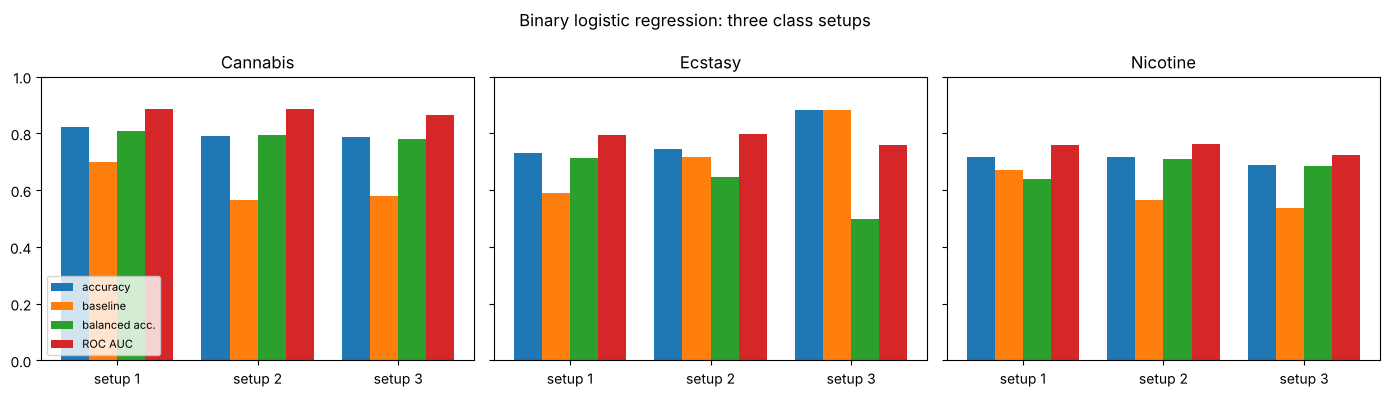

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, drug in zip(axes, binary_drugs):
    r = bin_res.loc[drug]
    x = np.arange(3); w = 0.2
    ax.bar(x - 1.5*w, r["accuracy"], w, label="accuracy")
    ax.bar(x - 0.5*w, r["baseline"], w, label="baseline")
    ax.bar(x + 0.5*w, r["balanced acc."], w, label="balanced acc.")
    ax.bar(x + 1.5*w, r["ROC AUC"], w, label="ROC AUC")
    ax.set_xticks(x); ax.set_xticklabels(["setup 1", "setup 2", "setup 3"]); ax.set_title(drug)
    ax.set_ylim(0, 1)
axes[0].legend(loc="lower left", fontsize=8)
plt.suptitle("Binary logistic regression: three class setups"); plt.tight_layout(); plt.show()

### Comments (d)
* With only two classes the problem becomes much easier: Cannabis reaches ≈ 0.79–0.82 accuracy and a ROC AUC ≈ 0.87–0.89, far better than the 7-class accuracy of part (a).
* **Accuracy must be compared with the baseline**, because the share of users changes between setups. The clearest example is **Ecstasy setup 3**: accuracy 0.881 looks like the best result, but it is exactly the baseline. Only 13 % of people are recent users, the model predicts "non-user" for everybody, the balanced accuracy is 0.50 and the F1 score is 0. This setup is in fact the **worst** one for Ecstasy.
* **Best setups** (judged by balanced accuracy, F1 and AUC, not by raw accuracy):
  * **Cannabis – setup 1** (balanced accuracy 0.81, F1 0.87, AUC 0.89). Setup 2 is almost as good (0.80 / 0.81 / 0.89), so the model separates users from non-users well with both thresholds.
  * **Ecstasy – setup 1** (balanced accuracy 0.72, F1 0.66). The performance drops as class 1 becomes rarer (setups 2 and 3).
  * **Nicotine – setup 2** (balanced accuracy 0.71, AUC 0.76). In setup 1 the accuracy is similar, but the balanced accuracy is lower (0.64): the model predicts "user" too often.
* In general the best setups are those where the two classes are **reasonably balanced**, and where the split separates people who never or only long ago used the drug from more recent users. Personality and demographics describe *who* is a user better than *how recently* they used it.

## Task 3 (5 points): Data normalization

##### Dataset: Linnerud 
* Number of records: 20
* Number of features: 3 + 3 (target/output features)
* Repository URL: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_linnerud.html 

##### Problems
__a.__ Look at features of Linnerud dataset, explore them and describe their characteristics. \
__b.__ Normalize these features using an appropriate method. Plot the probability density function of each feature with original and normalized data side-by-side.

---
# Solution Task 3: Data normalization (Linnerud)
### a. Explore the features
The Linnerud dataset has 20 middle-aged men. The 3 **features** are exercise results (`Chins` = number of chin-ups, `Situps` = number of sit-ups, `Jumps` = number of jumping jacks); the 3 **targets** are physiological measurements (`Weight`, `Waist`, `Pulse`). The task is about the 3 features.

In [16]:
from sklearn.datasets import load_linnerud
lin = load_linnerud(as_frame=True)
lin_X = lin.data
print(lin_X.head())
desc = lin_X.describe().T
desc["skewness"] = lin_X.skew()
desc["range"] = desc["max"] - desc["min"]
desc.round(2)

   Chins  Situps  Jumps
0    5.0   162.0   60.0
1    2.0   110.0   60.0
2   12.0   101.0  101.0
3   12.0   105.0   37.0
4   13.0   155.0   58.0


,count,mean,std,min,25%,50%,75%,max,skewness,range
Chins,20.0,9.45,5.29,1.0,4.75,11.5,13.25,17.0,-0.19,16.0
Situps,20.0,145.55,62.57,50.0,101.00,122.5,210.00,251.0,0.22,201.0
Jumps,20.0,70.30,51.28,25.0,39.50,54.0,85.25,250.0,2.48,225.0


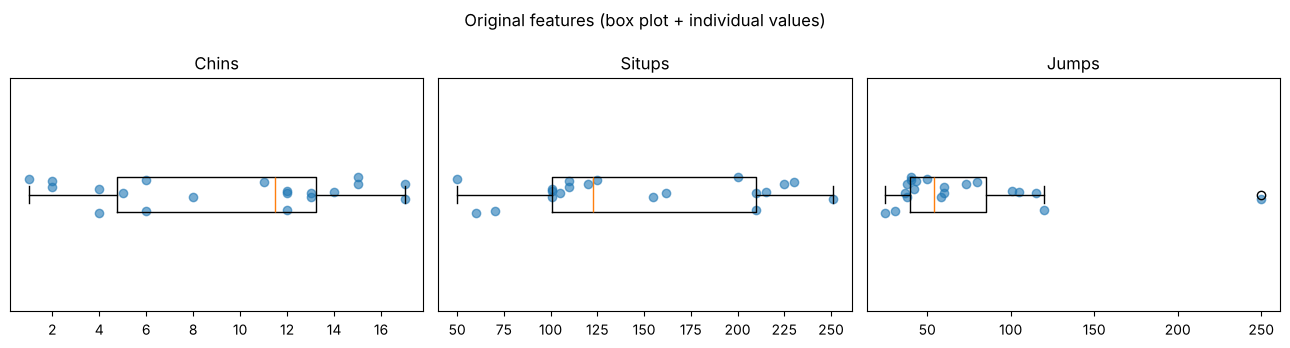

Correlation between the features:
        Chins  Situps  Jumps
Chins     1.0    0.70   0.50
Situps    0.7    1.00   0.67
Jumps     0.5    0.67   1.00


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, lin_X.columns):
    ax.boxplot(lin_X[col], vert=False)
    ax.scatter(lin_X[col], np.ones(len(lin_X)) + np.random.RandomState(0).uniform(-0.08, 0.08, len(lin_X)), alpha=0.6)
    ax.set_title(col); ax.set_yticks([])
plt.suptitle("Original features (box plot + individual values)"); plt.tight_layout(); plt.show()

print("Correlation between the features:")
print(lin_X.corr().round(2))

### Comments (a)
* **Small dataset:** only 20 observations, so all statistics (and the density estimates in b) are uncertain.
* **Very different scales:** Chins ranges 1–17 (mean ≈ 9.5), Situps 50–251 (mean ≈ 146) and Jumps 25–250 (mean ≈ 70). The standard deviations differ by more than a factor 10 (5.3 vs 62.6 and 51.3). A distance-based or regularized model would be dominated by Situps and Jumps if the data were not scaled.
* **Shapes:** Chins (skewness −0.19) and Situps (0.22) are roughly symmetric, both somewhat spread out with two groups of values (bimodal-like). **Jumps is strongly right-skewed** (skewness 2.48) because of one extreme value of 250 jumps, far above the other values (third quartile 85).
* **Correlation:** the three exercises are positively correlated (0.50–0.70): people who do many chin-ups also tend to do many sit-ups and jumps, which makes sense since they all measure physical fitness.

### b. Normalize the features
We use **standardization (z-score)** with `StandardScaler`: $z = (x - \mu)/\sigma$. Every feature then has mean 0 and standard deviation 1. We choose it because:
* the main problem of these features is their **different scales** (Chins ≈ 1–17, Situps ≈ 50–250), and after standardization they are directly comparable;
* it is the scaling expected by most of the models seen in the course (regularized linear models, SVM, KNN, PCA).

(Min–max scaling to [0, 1] would be very sensitive to the extreme `Jumps` value of 250, because that one value would define the maximum.)

Below we estimate the **probability density function (PDF)** of each feature with a Gaussian kernel density estimate (KDE), for the original and the normalized data side by side. A histogram is drawn behind the curve to show the 20 real values.

After standardization (mean ≈ 0, std ≈ 1):
      Chins  Situps  Jumps
mean   0.00   -0.00   0.00
std    1.03    1.03   1.03
min   -1.64   -1.57  -0.91
max    1.47    1.73   3.60


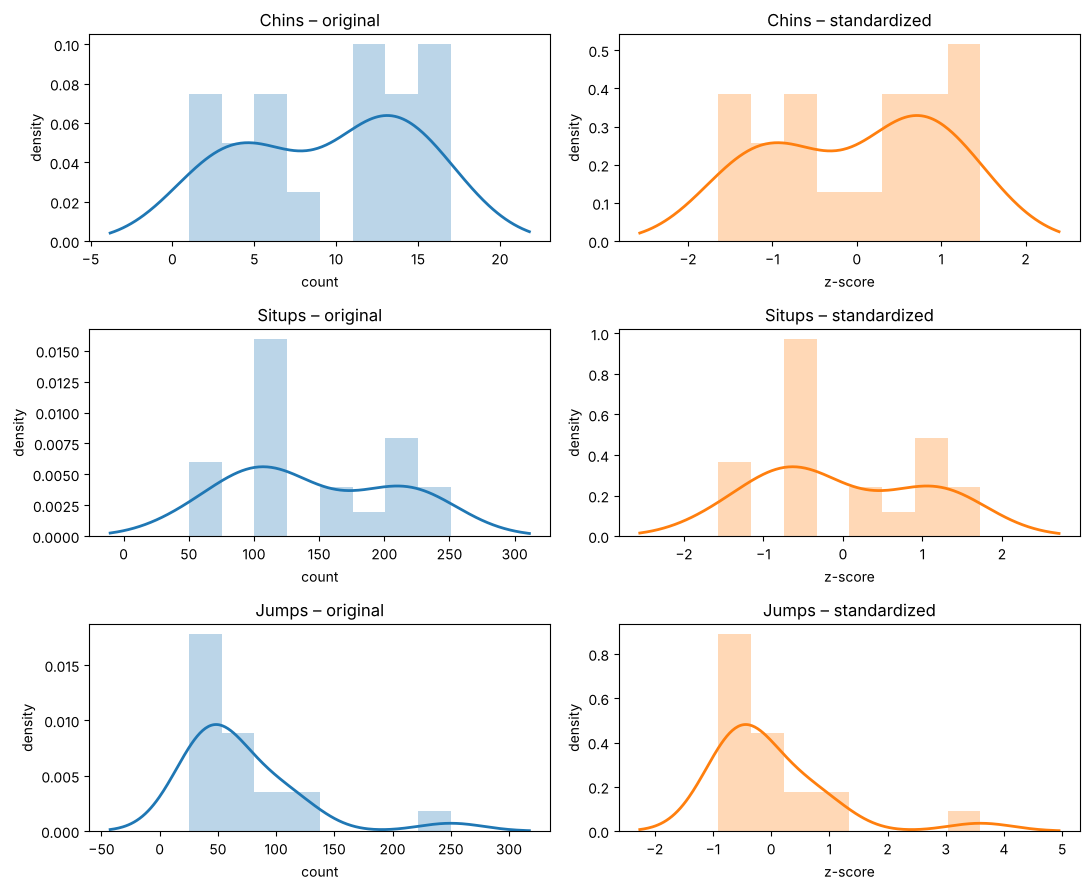

In [18]:
from scipy.stats import gaussian_kde

lin_scaled = pd.DataFrame(StandardScaler().fit_transform(lin_X), columns=lin_X.columns)
print("After standardization (mean ≈ 0, std ≈ 1):")
print(lin_scaled.describe().loc[["mean", "std", "min", "max"]].round(2))

def plot_pdf(ax, values, title, color):
    grid = np.linspace(values.min() - 0.3 * np.ptp(values), values.max() + 0.3 * np.ptp(values), 300)
    ax.hist(values, bins=8, density=True, alpha=0.3, color=color)
    ax.plot(grid, gaussian_kde(values)(grid), color=color, lw=2)
    ax.set_title(title); ax.set_ylabel("density")

fig, axes = plt.subplots(3, 2, figsize=(11, 9))
for i, col in enumerate(lin_X.columns):
    plot_pdf(axes[i, 0], lin_X[col].values, col + " – original", "tab:blue")
    plot_pdf(axes[i, 1], lin_scaled[col].values, col + " – standardized", "tab:orange")
    axes[i, 0].set_xlabel("count"); axes[i, 1].set_xlabel("z-score")
plt.tight_layout(); plt.show()

### Comments (b)
* After standardization all three features have mean 0 and standard deviation 1 (pandas shows 1.03 because it uses the sample formula with n−1, while `StandardScaler` uses n), so they are now on the **same scale** and can be compared directly: e.g. the Jumps outlier is 3.6 standard deviations above the mean.
* The side-by-side PDFs have **exactly the same shape** before and after standardization. Only the x-axis (shifted to 0 and rescaled) and the y-axis (density adjusted so the area stays 1) change. Standardization is a **linear transformation**: it changes location and scale, not the shape of the distribution. The bimodal-like shape of Chins and Situps and the skewness and outlier of Jumps remain.
* If a model needs more symmetric (more Gaussian-like) features, a non-linear transformation would be needed, e.g. a log or `PowerTransformer` (Box-Cox / Yeo-Johnson) for the skewed Jumps feature. With only 20 observations we prefer the simple and transparent standardization.

## Task 4 ( 10 points):  Dimensionality reduction and clustering
In case there is not Olivetti dataset, please change this into another dataset

##### Dataset: The Olivetti faces dataset
* Number of records: 400
* Number of features: 4096
* Repository URL: https://scikit-learn.org/stable/datasets/real_world.html

##### Problems
__a.__ Use KernelPCA\* for dimensionality reduction. Train a classifier at different numbers (at least 5 values) of dimensions, then check how model score changes as a function of the number of dimensions. \  
__b.__ Cluster the dataset into 40 clusters for at least 2 of the reduced data (done by KernelPCA in a). Print true class vs cluster distribution. Did you manage to recover the original clusters? Describe and comment your results. \


\* Marukatat, S. Tutorial on PCA and approximate PCA and approximate kernel PCA. Artif Intell Rev 56, 5445–5477 (2023). https://doi.org/10.1007/s10462-022-10297-z

---
# Solution Task 4: Dimensionality reduction and clustering (Olivetti faces)
### Load the data
400 grey-scale face images of 64×64 = 4096 pixels (values 0–1): **40 people, 10 images each**, with different lighting, facial expressions and glasses.

X: (400, 4096)  people: 40  images per person: 10


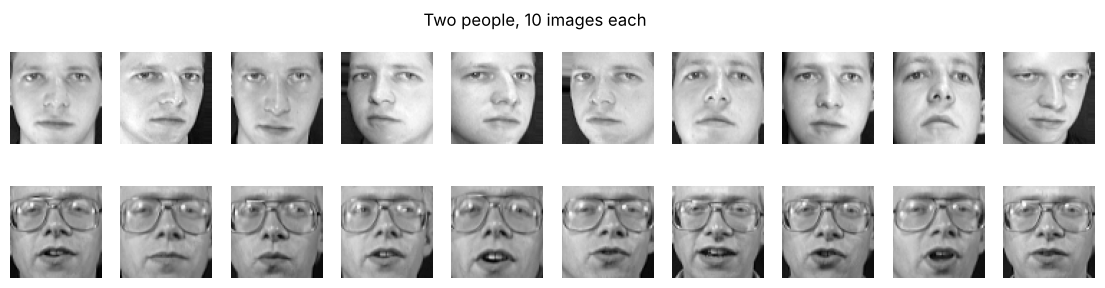

In [19]:
from sklearn.datasets import fetch_olivetti_faces
faces = fetch_olivetti_faces()
X_f, y_f = faces.data, faces.target
print("X:", X_f.shape, " people:", len(np.unique(y_f)), " images per person:", np.bincount(y_f)[0])

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, i in zip(axes.ravel(), list(range(10)) + list(range(10, 20))):
    ax.imshow(faces.images[i], cmap="gray"); ax.axis("off")
plt.suptitle("Two people, 10 images each"); plt.show()

### a. KernelPCA + classifier at different numbers of dimensions
**KernelPCA** is a non-linear version of PCA: it first maps the data with a kernel function (here the default-style **RBF** kernel) and then finds the directions of largest variance in that space. We keep `n_components` dimensions.

Steps, for each number of dimensions:
1. Split the 400 images into 75 % train / 25 % test, **stratified** so that each person has 7–8 training images and 2–3 test images.
2. Fit KernelPCA on the training images only, and transform train and test.
3. Standardize the KernelPCA components. (They have very small and unequal variances; without scaling, the default regularization of the classifier is far too strong and accuracy stays low.)
4. Train a **logistic regression** to recognize the 40 people and compute the test accuracy.

For comparison we also train the same classifier on all 4096 raw pixels.

   2 dimensions -> test accuracy 0.170
   5 dimensions -> test accuracy 0.590


  10 dimensions -> test accuracy 0.900


  20 dimensions -> test accuracy 0.930


  40 dimensions -> test accuracy 0.970
  80 dimensions -> test accuracy 0.980


 150 dimensions -> test accuracy 0.990


4096 raw pixels -> test accuracy 0.980


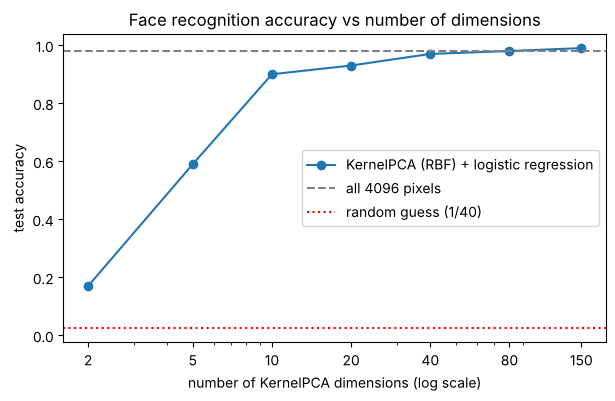

In [20]:
from sklearn.decomposition import KernelPCA

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_f, y_f, test_size=0.25, stratify=y_f, random_state=RANDOM_STATE)

dims = [2, 5, 10, 20, 40, 80, 150]
acc_by_dim = []
for n in dims:
    kpca = KernelPCA(n_components=n, kernel="rbf").fit(Xf_train)
    Z_tr, Z_te = kpca.transform(Xf_train), kpca.transform(Xf_test)
    zs = StandardScaler().fit(Z_tr)
    clf = LogisticRegression(max_iter=5000).fit(zs.transform(Z_tr), yf_train)
    acc_by_dim.append(clf.score(zs.transform(Z_te), yf_test))
    print("{:>4} dimensions -> test accuracy {:.3f}".format(n, acc_by_dim[-1]))

raw_clf = LogisticRegression(max_iter=5000).fit(Xf_train, yf_train)
raw_acc = raw_clf.score(Xf_test, yf_test)
print("4096 raw pixels -> test accuracy {:.3f}".format(raw_acc))

plt.figure(figsize=(7, 4))
plt.plot(dims, acc_by_dim, "o-", label="KernelPCA (RBF) + logistic regression")
plt.axhline(raw_acc, ls="--", color="gray", label="all 4096 pixels")
plt.axhline(1/40, ls=":", color="red", label="random guess (1/40)")
plt.xscale("log"); plt.xticks(dims, dims)
plt.xlabel("number of KernelPCA dimensions (log scale)"); plt.ylabel("test accuracy")
plt.legend(); plt.title("Face recognition accuracy vs number of dimensions"); plt.show()

### Comments (a)
* The accuracy increases quickly with the number of dimensions: 2 dimensions are far too few (0.17, still better than a random guess of 0.025), 10 dimensions already give 0.90, and 40 dimensions 0.97.
* After about 40–80 dimensions the curve **flattens** (0.97–0.99): the extra components carry little new information. With 80 dimensions we reach the same accuracy as with all 4096 pixels (0.98), i.e. **about 50 times fewer features**, which makes training faster and the model smaller.
* This works because face images are very redundant: neighbouring pixels are highly correlated, and the differences between people can be described with a small number of directions ("eigenfaces" in kernel space).
* Note: the test set has 100 images, so one wrong image changes the accuracy by 0.01. The differences between 40, 80 and 150 dimensions (0.97 / 0.98 / 0.99) are only 1–2 images.

### b. K-means with 40 clusters on the reduced data
Now we forget the labels and ask **K-means** to group the 400 images into 40 clusters, hoping that each cluster = one person. We fit KernelPCA on all 400 images (clustering is unsupervised, there is no train/test split) and try **3 reduced versions: 10, 40 and 80 dimensions**.

To compare clusters with the true people we use:
* **contingency table** (true person × cluster): how the 10 images of each person are spread over the clusters;
* **purity**: for each cluster, take its most frequent person; purity = share of images that belong to that person (1 = every cluster contains one person only);
* **Adjusted Rand Index (ARI)**: agreement between clusters and true people (1 = perfect, 0 = random);
* number of people whose images are **mostly together** (≥ 8 of 10 images in the same cluster).

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

cluster_results, tables = [], {}
for n in [10, 40, 80]:
    Z = KernelPCA(n_components=n, kernel="rbf").fit_transform(X_f)
    labels = KMeans(n_clusters=40, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    ct = pd.crosstab(pd.Series(y_f, name="true person"), pd.Series(labels, name="cluster"))
    tables[n] = ct
    cluster_results.append({"dimensions": n,
                            "purity": ct.max(axis=0).sum() / len(y_f),
                            "ARI": adjusted_rand_score(y_f, labels),
                            "people with >=8/10 images together": int((ct.max(axis=1) >= 8).sum()),
                            "people with all 10 together": int((ct.max(axis=1) == 10).sum()),
                            "clusters with only one person": int(((ct > 0).sum(axis=0) == 1).sum())})
pd.DataFrame(cluster_results).set_index("dimensions").round(3)

,purity,ARI,people with >=8/10 images together,people with all 10 together,clusters with only one person
dimensions,,,,,
10,0.578,0.394,10,7,12
40,0.668,0.481,15,9,15
80,0.652,0.458,17,8,16


**True class vs cluster distribution.** Printing the full 40 × 40 table is hard to read, so we show it as a heat map (rows = true person, columns = clusters reordered so that each person's main cluster is on the diagonal), and print, for each person, how its 10 images are spread over clusters.

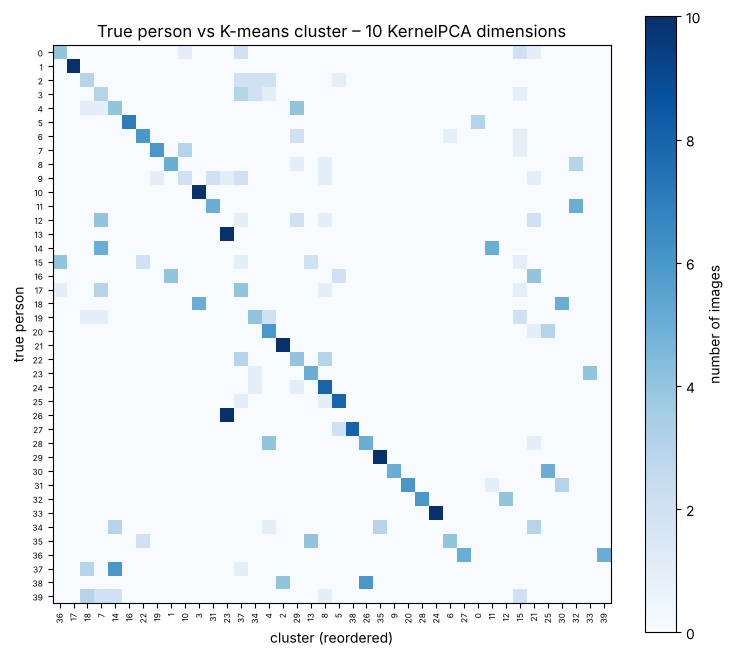

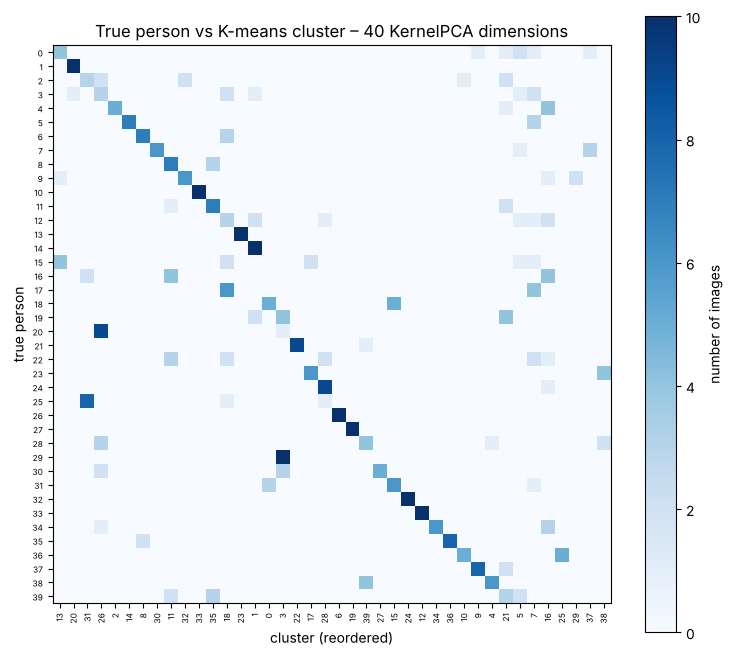

Distribution of each person's 10 images over the clusters (40 dimensions, cluster:count):
true person
0     c13:4, c5:2, c7:1, c9:1, c21:1, c37:1
1                                    c20:10
2         c31:3, c26:2, c21:2, c32:2, c10:1
3     c26:3, c7:2, c18:2, c1:1, c5:1, c20:1
4                        c2:5, c16:4, c21:1
5                               c14:7, c7:3
6                               c8:7, c18:3
7                        c30:6, c37:3, c5:1
8                              c11:7, c35:3
9                c32:6, c29:2, c16:1, c13:1
10                                   c33:10
11                      c35:7, c21:2, c11:1
12    c18:3, c1:2, c16:2, c5:1, c7:1, c28:1
13                                   c23:10
14                                    c1:10
15          c13:4, c18:2, c17:2, c5:1, c7:1
16                      c11:4, c16:4, c31:2
17                              c18:6, c7:4
18                              c0:5, c15:5
19                        c3:4, c21:4, c1:2
20                

In [22]:
best_n = max(cluster_results, key=lambda r: r["ARI"])["dimensions"]
for n in [10, best_n]:
    ct = tables[n]
    order = list(dict.fromkeys(ct.idxmax(axis=1).tolist() + list(ct.columns)))   # main cluster of each person first
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(ct[order].values, cmap="Blues", vmin=0, vmax=10)
    ax.set_xlabel("cluster (reordered)"); ax.set_ylabel("true person")
    ax.set_xticks(range(40)); ax.set_xticklabels(order, fontsize=6, rotation=90)
    ax.set_yticks(range(40)); ax.set_yticklabels(ct.index, fontsize=6)
    plt.colorbar(im, label="number of images"); plt.title("True person vs K-means cluster – {} KernelPCA dimensions".format(n))
    plt.show()

ct = tables[best_n]
spread = ct.apply(lambda r: ", ".join("c{}:{}".format(c, v) for c, v in r[r > 0].sort_values(ascending=False).items()), axis=1)
print("Distribution of each person's 10 images over the clusters ({} dimensions, cluster:count):".format(best_n))
print(spread.to_string())

### Comments (b)
* **Partly recovered.** K-means finds a part of the identities but not all of them. With 40 dimensions (the best ARI ≈ 0.48, purity ≈ 0.67), 9 of the 40 people have all their 10 images in one cluster (e.g. people 1, 10, 13, 14, 26, 27, 29, 32, 33), and 15 people have at least 8 of 10 images together. In the heat map these people form the dark diagonal.
* **Typical errors:** (1) one person split over two or more clusters (e.g. person 18: 5 + 5 images, person 36: 5 + 5), probably because of different lighting, glasses or head pose in their images; (2) one cluster mixing several people (e.g. clusters 7, 16, 18 and 21 collect images from many different people). The "messy" people (e.g. 0, 2, 3, 12, 22, 39) have their images spread over 5–6 clusters.
* **Effect of the number of dimensions:** 10 dimensions give clearly worse clusters (ARI ≈ 0.39, purity ≈ 0.58) because too much information is lost. 40 and 80 dimensions are similar (ARI ≈ 0.48 and 0.46), so more dimensions do not help beyond about 40: the extra components mostly add noise, and distances in high dimensions become less informative for K-means.
* **Why clustering is much harder than classification (a):** the classifier learned from labelled examples which differences matter (identity) and which do not (lighting, expression). K-means only groups images that are close to each other, and two images of different people under the same lighting can be closer than two images of the same person under different lighting. K-means also assumes round clusters of similar size, which does not fit the data exactly, and its result depends on the random initialization.

---
# Final remarks
* All results use `random_state=42`; other random splits will give slightly different numbers, especially for the small datasets (Linnerud, Olivetti test set of 100 images, rare drug classes).
* Parameters were selected on validation data taken from the training set, and the test set was used only for the final evaluation. A more robust choice would use cross-validation (Lecture 3).